# ERC circularité · 03 · Fiabilité

**Question** : une pièce réparée ou récupérée, reposée sur un FRU, tombe-t-elle en panne plus vite qu'une pièce neuve ?

**Décision éclairée** : pour quelles références le réemploi est acceptable du point de vue de la tenue en service, et quelles précautions il demande (test, âge maximal du donneur).

**Ce que le fichier de fiabilité peut dire, et ce qu'il ne peut pas dire** : il ne contient que des **défaillances précoces**, aucune pièce encore en service. Il donne donc la *forme* de la défaillance (plutôt au début, au hasard, ou par usure) et, si l'on connaît le nombre de pièces posées sur la même période, un *taux de défaillance précoce* par origine de pièce. Il ne donne pas de durée de vie. L'origine d'une pièce posée (neuve, réparée, récupérée) est lue dans le suffixe de sa référence.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="fiabilite")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


  étape flux         14 artefacts → artefacts/02_flux/


  étape fiabilite    11 artefacts → artefacts/03_fiabilite/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## 1. Taux de défaillance précoce, par référence et par origine

Défaillances précoces rapportées aux pièces posées sur la même période. Le point est le taux moyen, le trait son intervalle à 90 %.

**Lecture** : comparer, pour une même référence, la pièce neuve aux pièces réparées ou récupérées. Deux intervalles qui se recouvrent ne permettent pas de conclure. La colonne « Rapport au neuf » divise le taux d'une origine par celui de la pièce neuve : 2 signifie deux fois plus de défaillances précoces. Quand la table donne aussi un rapport bas et un rapport haut, ils encadrent ce rapport : si 1 est entre les deux, l'écart avec la pièce neuve n'est pas établi.

**Limites** : sans le nombre de pièces posées, aucun taux n'est calculé et la figure n'est pas produite. Avec peu de pièces posées, l'intervalle est large : c'est l'information, pas un défaut.

**Taux de défaillance précoce.** Pour chaque référence, le taux de défaillance précoce d'une pièce neuve, réparée ou récupérée, avec son intervalle à 90 %. Lecture : deux intervalles qui se recouvrent ne permettent pas de dire qu'une origine est moins fiable que l'autre.

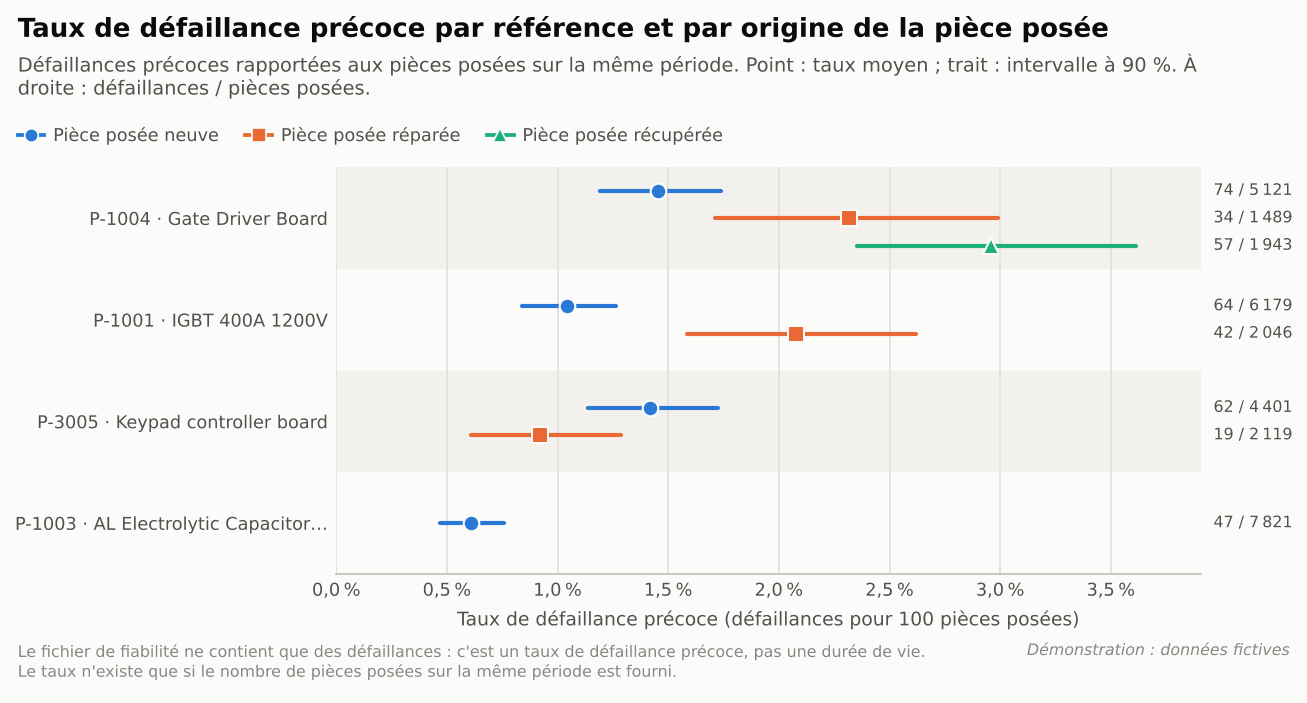

In [3]:
aff.figures(ctx, "fiabilite", "Taux de défaillance précoce")

In [4]:
aff.table(ctx, "fiabilite", "Fiabilité par référence", colonnes=["Référence", "Origine posée", "Défaillances ELF", "Pièces posées (même période)",
          "Taux ELF moyen", "IC90 bas", "IC90 haut", "Rapport au neuf (taux)", "Rapport bas (5 %)", "Rapport haut (95 %)", "Lecture du rapport",
          "elf_days médiane", "Part à J0 (DOA)"])

Référence,Origine posée,Défaillances ELF,Pièces posées (même période),Taux ELF moyen,IC90 bas,IC90 haut,Rapport au neuf (taux),Rapport bas (5 %),Rapport haut (95 %),Lecture du rapport,elf_days médiane,Part à J0 (DOA)
P-1004,Neuve,74,5 121,"1,45 %","1,19 %","1,74 %","1,00",,,référence (pièce neuve),"40,00","4,05 %"
P-1001,Neuve,64,6 179,"1,04 %","0,84 %","1,26 %","1,00",,,référence (pièce neuve),"27,50","1,56 %"
P-3005,Neuve,62,4 401,"1,42 %","1,14 %","1,73 %","1,00",,,référence (pièce neuve),"40,00","4,84 %"
P-1004,Récupérée,57,1 943,"2,96 %","2,35 %","3,62 %","2,03","1,52","2,69",moins fiable que le neuf,"32,00","3,51 %"
P-1003,Neuve,47,7 821,"0,61 %","0,47 %","0,76 %","1,00",,,référence (pièce neuve),"66,00","0,00 %"
P-1001,Réparée,42,2 046,"2,08 %","1,59 %","2,62 %","1,99","1,43","2,72",moins fiable que le neuf,"36,50","4,76 %"
P-1004,Réparée,34,1 489,"2,32 %","1,71 %","2,99 %","1,59","1,12","2,20",moins fiable que le neuf,"20,50","8,82 %"
P-3005,Réparée,19,2 119,"0,92 %","0,61 %","1,29 %","0,65","0,41","0,96",plus fiable que le neuf,"49,00","5,26 %"


## 2. À quelle vitesse surviennent les défaillances ?

Courbes de Kaplan-Meier des références qui cumulent le plus de défaillances, une courbe par origine.

**Lecture** : une courbe qui descend plus tôt signale des défaillances plus rapides après la pose. **Limite** : toutes les courbes finissent à zéro, parce que le fichier ne contient que des pièces qui ont défailli. Ce ne sont ni des durées de vie ni des probabilités de panne.

**Kaplan-Meier.** Courbes de Kaplan-Meier des références qui cumulent le plus de défaillances précoces, une courbe par origine de la pièce posée. Lecture : une courbe qui descend plus tôt signale des défaillances plus rapides après la pose.

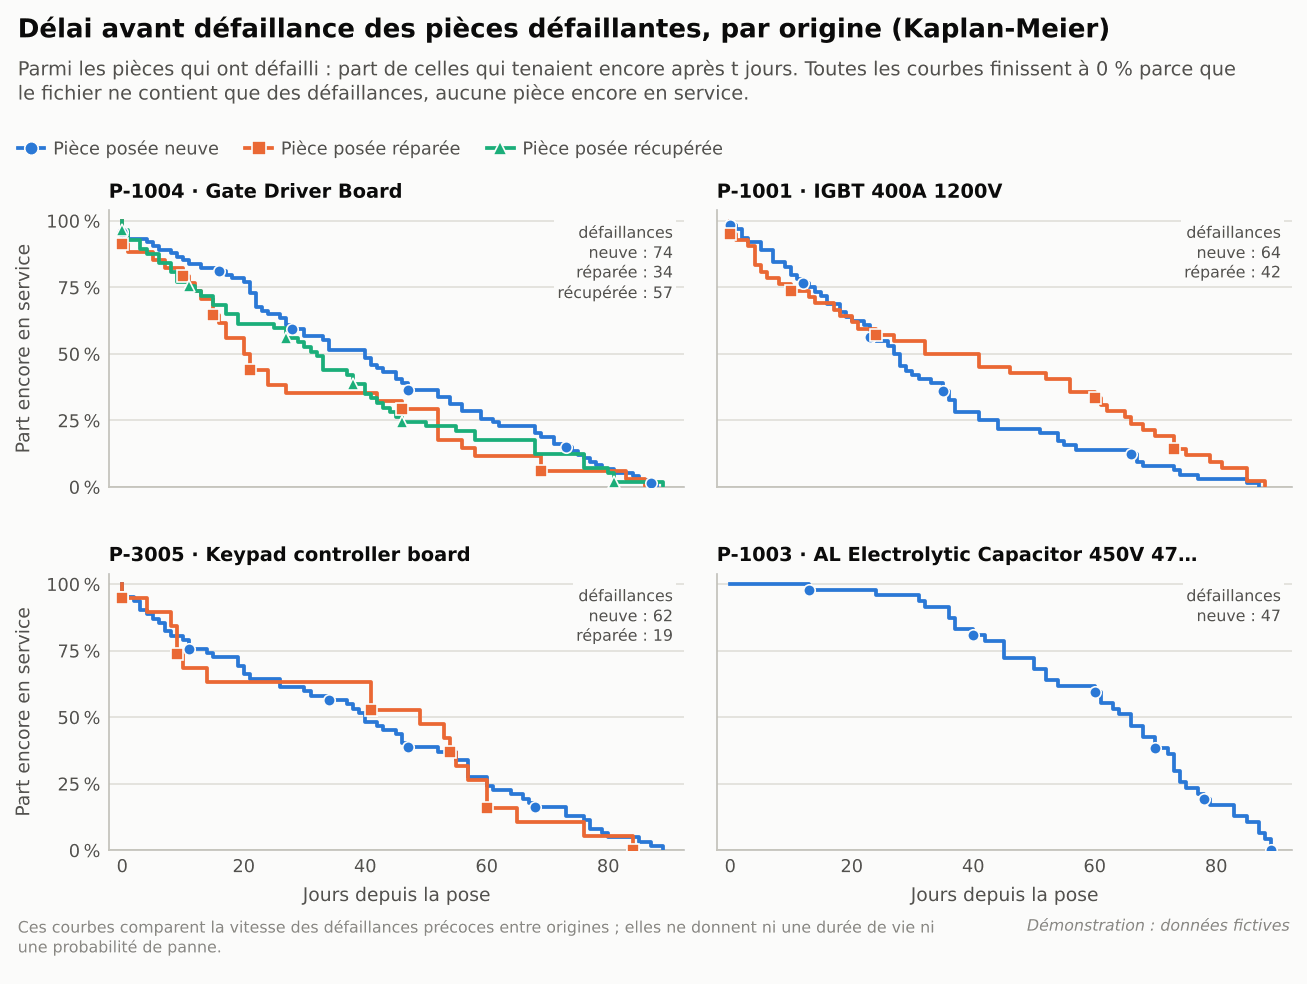

In [5]:
aff.figures(ctx, "fiabilite", "Kaplan-Meier")

## 3. Forme de la défaillance (Weibull)

La forme *k* dit comment le risque évolue avec l'âge de la pièce :

- *k* < 1 : les défaillances surviennent surtout au début. Une pièce qui a déjà fonctionné est plus sûre qu'une neuve ; un test avant réemploi est utile.
- *k* proche de 1 : le risque ne dépend pas de l'âge. Le réemploi est neutre.
- *k* > 1 : le risque croît avec l'âge (usure). Le réemploi n'a de sens que si l'âge de la pièce donneuse est connu et faible.

**Limites** : *k* est estimé sur des défaillances précoces seulement ; il décrit le début de vie. Avec moins de trois défaillances, il n'est pas calculé. Quand l'intervalle d'incertitude sur *k* n'est pas tracé, c'est qu'il n'est pas calculé : avec une poignée de défaillances, *k* est imprécis.

**Forme de Weibull.** La forme k dit comment le risque de défaillance évolue avec l'âge de la pièce, ce qui conditionne l'intérêt d'un réemploi : sous 1, une pièce qui a déjà tourné est plus sûre qu'une neuve ; au-dessus de 1, l'âge du donneur compte.

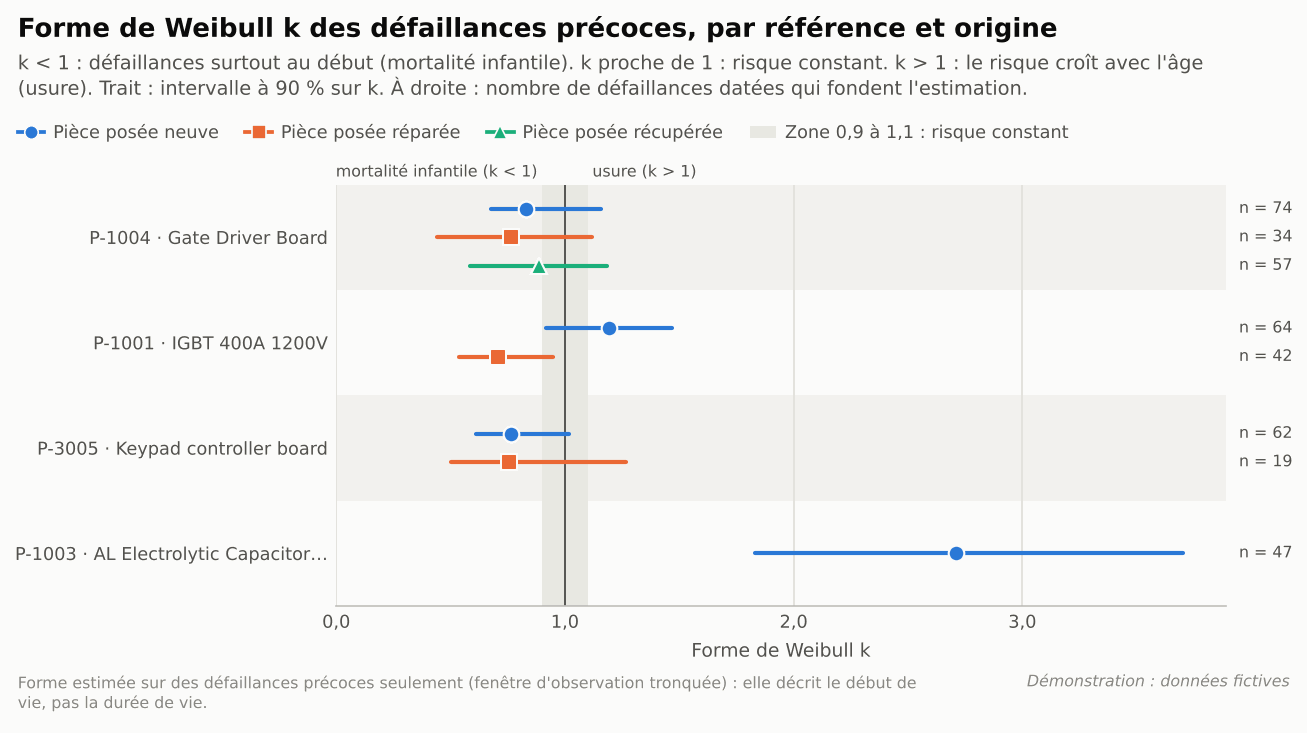

In [6]:
aff.figures(ctx, "fiabilite", "Forme de Weibull")

In [7]:
aff.table(ctx, "fiabilite", "Fiabilité par référence", colonnes=["Référence", "Origine posée", "elf_days renseigné", "Forme Weibull k", "k bas (5 %)", "k haut (95 %)",
          "Lecture de la forme", "Note"])

Référence,Origine posée,elf_days renseigné,Forme Weibull k,k bas (5 %),k haut (95 %),Lecture de la forme,Note
P-1004,Neuve,74,"0,83","0,68","1,16",indéterminé : pas assez de défaillances pour conclure,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)
P-1001,Neuve,64,"1,19","0,92","1,47",indéterminé : pas assez de défaillances pour conclure,"échelle λ faiblement identifiable (fenêtre tronquée, pas de survivants) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)"
P-3005,Neuve,62,"0,76","0,61","1,02",indéterminé : pas assez de défaillances pour conclure,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)
P-1004,Récupérée,57,"0,88","0,58","1,18",indéterminé : pas assez de défaillances pour conclure,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)
P-1003,Neuve,47,"2,71","1,83","3,70",usure : le risque croît avec l'âge ; réemploi seulement si l'âge du donneur est connu et faible,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)
P-1001,Réparée,42,"0,71","0,54","0,95",indéterminé : pas assez de défaillances pour conclure,"échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j) ; tendance visible sur l'intervalle à 90 %, non retenue par la lecture (intervalle à 95 %)"
P-1004,Réparée,34,"0,76","0,44","1,12",indéterminé : pas assez de défaillances pour conclure,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)
P-3005,Réparée,19,"0,76","0,50","1,27",indéterminé : pas assez de défaillances pour conclure,échelle λ non identifiable (données compatibles avec une durée de vie très grande devant la fenêtre) : aucune durée de vie n'en est tirée ; fenêtre non fournie : prise égale au plus grand délai du fichier (89 j)


## 4. Ce que change l'âge de la pièce donneuse (illustration)

Calcul théorique, sur une échelle de temps arbitraire : probabilité qu'une pièce déjà âgée tienne encore la durée de garantie, selon la forme *k*. **Ce ne sont pas des données de l'atelier** : la figure sert seulement à lire la précédente.

Les a priori physiques rappellent, pour deux familles de pièces, le mécanisme d'usure attendu et les paramètres à lire sur la fiche du fabricant.

**Âge du donneur (illustration).** Illustration théorique, sans données de l'atelier : selon la forme k, une pièce déjà âgée tient mieux (k < 1), aussi bien (k = 1) ou moins bien (k > 1) la période de garantie qu'une pièce neuve. Sert à lire la figure des formes k.

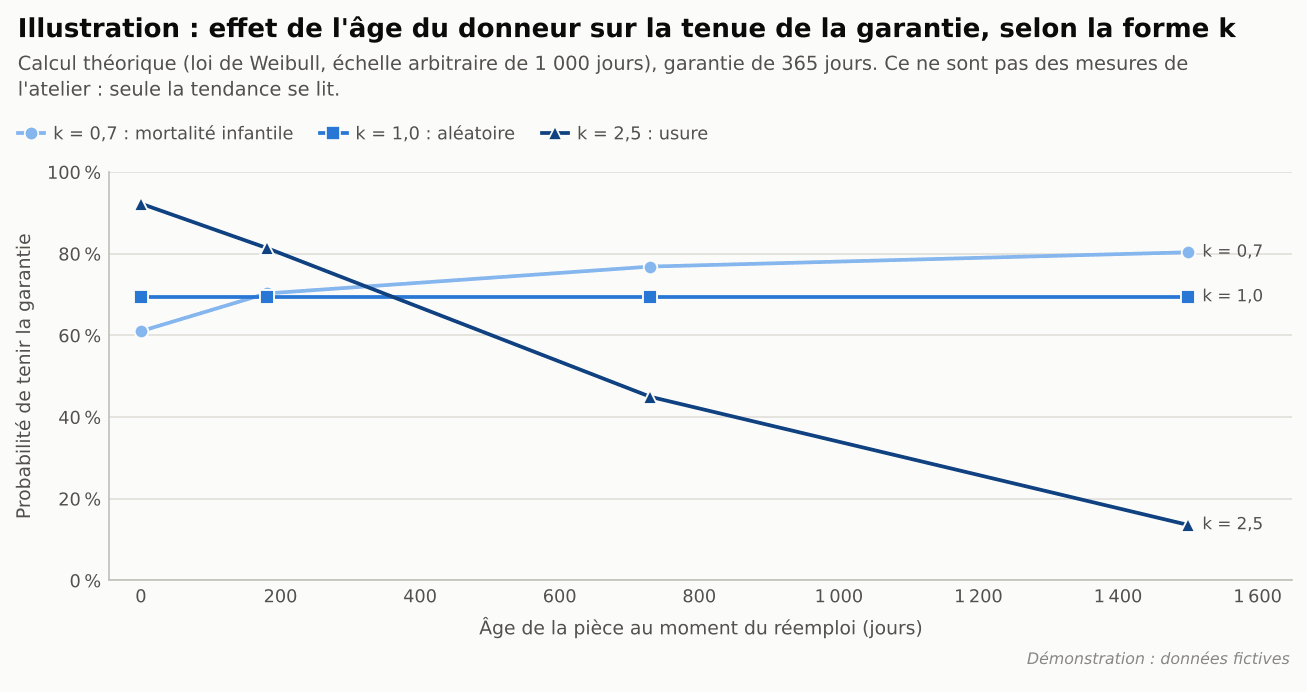

In [8]:
aff.figures(ctx, "fiabilite", "Âge du donneur (illustration)")

In [9]:
aff.table(ctx, "fiabilite", "A priori physiques")

Type de pièce,Mécanisme,Loi,Paramètres à lire,Source
Condensateur électrolytique,Séchage de l'électrolyte (usure),La vie double tous les 10 °C sous la température nominale,"Vie nominale (h) et température nominale, température de service","Fiche du fabricant, mesure dans le FRU"
IGBT / module de puissance,Fatigue en cyclage thermique,"Coffin-Manson : nombre de cycles ∝ ΔTj^-n, n ≈ 5","Amplitude de température de jonction ΔTj, constante du module","Fiche du fabricant, conception"


## 5. La pré-sélection, avec la fiabilité

La pré-sélection du notebook 01, complétée du critère « fiabilité du réemploi » pour les références où un rapport au neuf a pu être calculé. Le front de Pareto peut donc changer.

**Lecture** : la colonne « Fiabilité réemploi (1/rapport) » est l'inverse du rapport au neuf, pris sur l'origine la plus favorable (réparée ou récupérée). Au-dessus de 1 : moins de défaillances précoces que la pièce neuve ; en dessous : davantage.

**Limites** : le critère n'existe que pour les références présentes dans le fichier de fiabilité avec une origine réparée ou récupérée ; ailleurs il reste vide et la pièce y est classée au plus bas. Il ne tient pas compte de l'incertitude du rapport : fondé sur deux ou trois défaillances, il est fragile (voir les intervalles de la section 1).

**Pré-sélection avec fiabilité.** Chaque point est une pièce : en abscisse le nombre de FRU rebutées qui la contiennent (gisement), en ordonnée son MMICV total consommé (valeur). Les points bleus forment le front de Pareto : ce sont les candidates à examiner en premier. La fiabilité du réemploi est ajoutée aux critères quand elle a pu être calculée : le front peut différer de celui de l'étape classement.

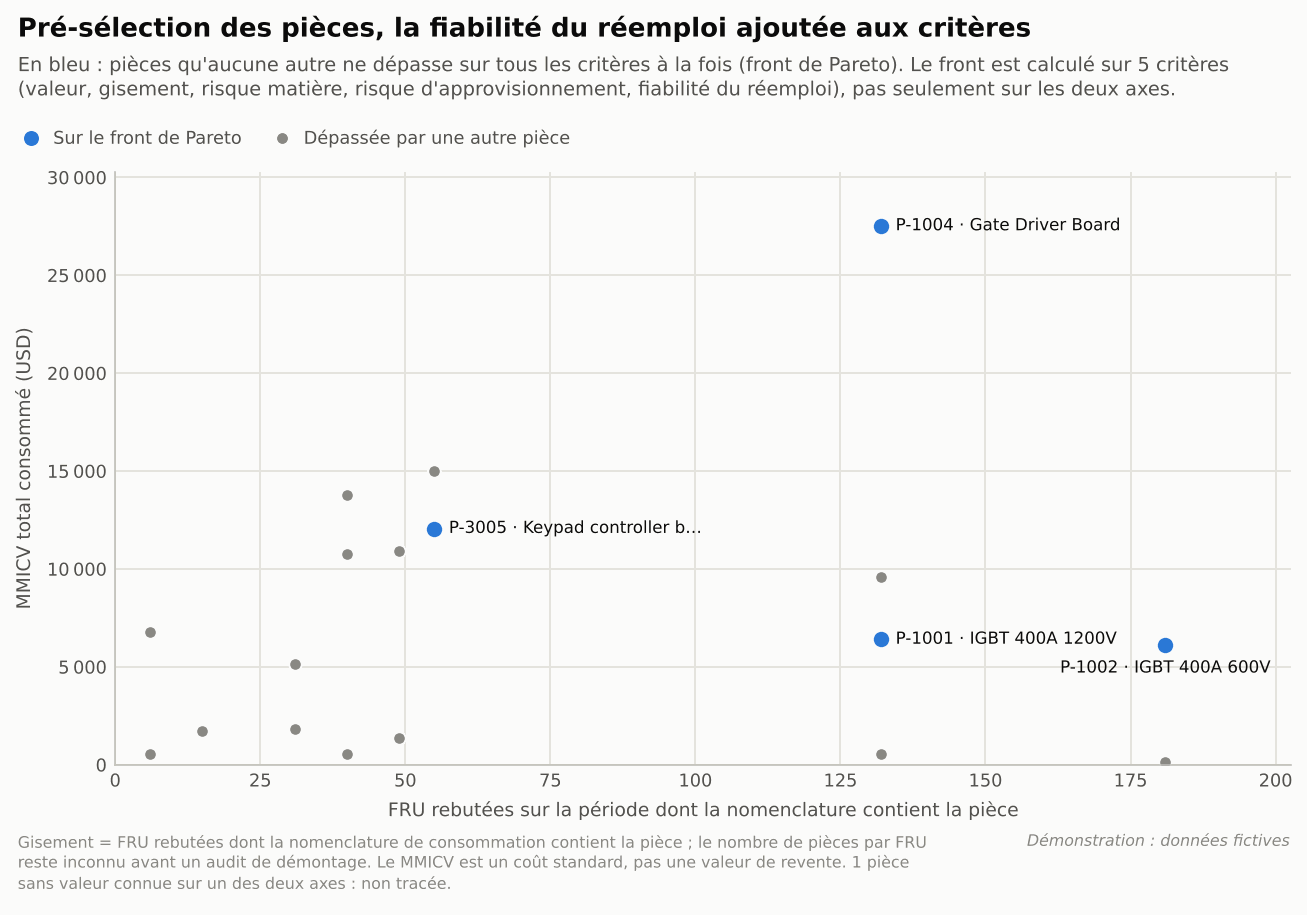

In [10]:
aff.figures(ctx, "fiabilite", "Pré-sélection avec fiabilité")

In [11]:
aff.table(ctx, "fiabilite", "Priorisation avec fiabilité", colonnes=["Référence", "Description", "Sur le front de Pareto", "MMICV total (USD)", "FRU rebutées (nomenclature)",
          "Score risque matière (0-1)", "Risque supply retenu", "Fiabilité réemploi (1/rapport)", "Note (poids égaux, indicatif)"])

Référence,Description,Sur le front de Pareto,MMICV total (USD),FRU rebutées (nomenclature),Score risque matière (0-1),Risque supply retenu,Fiabilité réemploi (1/rapport),"Note (poids égaux, indicatif)"
P-1004,Gate Driver Board,oui,27 520,132,"1,00","0,62","0,63","0,802"
P-3005,Keypad controller board,oui,12 060,55,"1,00","0,38","1,54","0,686"
P-1001,IGBT 400A 1200V,oui,6 400,132,"0,75","1,00","0,50","0,655"
P-1002,IGBT 400A 600V,oui,6 100,181,"0,75","1,00",,"0,614"
P-3002,Tête de joystick,non,15 008,55,"0,00",,,"0,336"
P-3001,Coque boîtier gris,non,13 800,40,"0,00",,,"0,278"
P-2001,Power supply board,non,10 920,49,"1,00","0,46",,"0,479"
P-3004,Cable harness boîtier,non,10 780,40,"0,25",,,"0,287"
P-1005,Control board assembly,non,9 610,132,"1,00","0,62",,"0,602"
P-6001,Mainboard station,non,6 800,6,"1,00","0,60",,"0,399"


## Notes de l'étape

Nombre de défaillances lues, présence du dénominateur (pièces posées), fenêtre d'observation, durée de garantie utilisée.

In [12]:
aff.notes(ctx, "fiabilite")

Élément,Valeur
Défaillances lues dans le fichier de fiabilité,399
Pièces posées (dénominateur),chargé
Fenêtre d'observation (jours),89
Garantie (jours),365
Critères actifs,"MMICV total (USD), FRU rebutées (nomenclature), Score risque matière (0-1), Risque supply retenu, Fiabilité réemploi (1/rapport)"


---
Notebook suivant : **04_Modele_de_Rex**. Tous les fichiers affichés ici sont dans le dossier des artefacts, étape `03_fiabilite` ; un classeur Excel du même nom réunit les tables de l'étape.